# Freight-rate predication prject
## Objective:
Use Data from previous months to predict the posted rate in the last quarter of year 2026.

## Analysis

In [24]:
# Libraries Importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor

train_test_df = pd.read_csv('train-test.csv')
validation_df = pd.read_csv('validation.csv')

In [25]:
display(train_test_df.describe())
display(validation_df.describe())

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,0.926913,2.051334
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,0.074109,0.219804
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,1.098950,2.896350


In [26]:
# General Analysis
display(train_test_df.describe())

# show siszes of train-test and validation data
print("Train-Test Data Size:", train_test_df.shape)
print("Validation Data Size:", validation_df.shape)

# show number of null or missing values in train-test and validation data
print("Train-Test Data Null Values:\n", train_test_df.isnull().sum())
print("Validation Data Null Values:\n", validation_df.isnull().sum())

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


Train-Test Data Size: (48000, 14)
Validation Data Size: (12000, 13)
Train-Test Data Null Values:
 load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64
Validation Data Null Values:
 load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64


### 1. EDA Data Exploration
#### 1.1 Features exploration

In [27]:
# Logging all possible features to check, and what will
# bes useful for training and testing the model
feature_cols = train_test_df.columns[1:-1]
print("Feature Columns:", feature_cols.to_list())

display(train_test_df.head())

Feature Columns: ['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


#### 1.1.1 Pickup_Delivery analysis

In [28]:
# For train-test data
pick_train_test_df = set(train_test_df["pickup"].to_list())
delivery_train_test_df = set(train_test_df["delivery"].to_list())

all_unique_cities_train_test = pick_train_test_df.union(delivery_train_test_df)
possible_routes = len(pick_train_test_df) * len(delivery_train_test_df)
existing_routes = len(train_test_df)

print("Pickup Locations in Train-Test DataFrame:", len(pick_train_test_df))
print("Delivery Locations in Train-Test DataFrame:", len(delivery_train_test_df))
print("All Unique Cities:", len(all_unique_cities_train_test))
print("Possible Routes:", possible_routes)
print("Existing Routes:", existing_routes)

Pickup Locations in Train-Test DataFrame: 64
Delivery Locations in Train-Test DataFrame: 64
All Unique Cities: 64
Possible Routes: 4096
Existing Routes: 48000


In [29]:
# For validation data
pick_val_df = set(validation_df["pickup"].to_list())
delivery_val_df = set(validation_df["delivery"].to_list())

all_unique_cities_val = pick_val_df.union(delivery_val_df)
possible_routes = len(pick_val_df) * len(delivery_val_df)
existing_routes = len(validation_df)

print("Pickup Locations in Validation DataFrame:", len(pick_val_df))
print("Delivery Locations in Validation DataFrame:", len(delivery_val_df))
print("All Unique Cities:", len(all_unique_cities_val))
print("Possible Routes:", possible_routes)
print("Existing Routes:", existing_routes)

Pickup Locations in Validation DataFrame: 72
Delivery Locations in Validation DataFrame: 72
All Unique Cities: 72
Possible Routes: 5184
Existing Routes: 12000


In [30]:
# show different cities in train-test and validation data
diff_cities = all_unique_cities_val - all_unique_cities_train_test
print("Cities in Validation Data but not in Train-Test Data:", diff_cities)

Cities in Validation Data but not in Train-Test Data: {'Knoxville', 'Allentown', 'Norfolk', 'San Diego', 'Charlotte', 'Jackson', 'Chicago', 'Laredo'}


In [31]:
# build routes as "pickup-delivery"
routes_train_test = set(train_test_df['pickup'].astype(str) + '-' + train_test_df['delivery'].astype(str))
routes_val = set(validation_df['pickup'].astype(str) + '-' + validation_df['delivery'].astype(str))

# compare the two route sets
common_routes = routes_train_test & routes_val
only_train_test = routes_train_test - routes_val
only_val = routes_val - routes_train_test
union_routes = routes_train_test | routes_val

print("Common routes:", len(common_routes))
print("Only in train-test:", len(only_train_test))
print("Only in val:", len(only_val))
print("Union of routes:", len(union_routes))


Common routes: 3478
Only in train-test: 536
Only in val: 736
Union of routes: 4750


### 1.1.2 Longitude-Langtiude association with pickup and delivery

In [32]:
# Make sure each city has one longitude and latitude, and that they are consistent across both datasets
pickup_train_test = train_test_df[['pickup', 'pickup_lat', 'pickup_lon']].drop_duplicates()
delivery_train_test = train_test_df[['delivery', 'delivery_lat', 'delivery_lon']].drop_duplicates()

pickup_val = validation_df[['pickup', 'pickup_lat', 'pickup_lon']].drop_duplicates()
delivery_val = validation_df[['delivery', 'delivery_lat', 'delivery_lon']].drop_duplicates()


print("Unique Cities in Validation DataFrame:", delivery_val.shape[0])
print("Unique Cities in Train-Test DataFrame:", delivery_train_test.shape[0])
print("Unique Cities in Validation DataFrame:", pickup_val.shape[0])
print("Unique Cities in Train-Test DataFrame:", pickup_train_test.shape[0])

Unique Cities in Validation DataFrame: 72
Unique Cities in Train-Test DataFrame: 64
Unique Cities in Validation DataFrame: 72
Unique Cities in Train-Test DataFrame: 64


### 1.1.3 Does city value impact posted rate whatever the distance ?

In [33]:
# Build the route column (copy() avoids the SettingWithCopyWarning)
dist_train_test = train_test_df.copy()
dist_train_test['route'] = dist_train_test['pickup'].astype(str) + '-' + dist_train_test['delivery'].astype(str)

# Count rows per route, keep only routes that appear more than once
# (a route with a single row can't show any variation)
route_counts = dist_train_test['route'].value_counts()
repeated_routes = route_counts[route_counts > 1].index

# Pick one route at random. No random_state, so each run differs.
random_route_name = pd.Series(repeated_routes).sample(n=1).iloc[0]

# Keep ALL rows that belong to that route
route_df = dist_train_test[dist_train_test['route'] == random_route_name]

# Keep only route, distance , market_index, weight, posted_rate
route_df = route_df[['route', 'distance', 'market_index', 'weight', 'posted_rate']]
display(route_df)

,route,distance,market_index,weight,posted_rate
7083,Indianapolis-Tucson,1747.4,1.02549,35301.0,3211.69
12518,Indianapolis-Tucson,1721.0,1.14071,33004.0,3256.61
15826,Indianapolis-Tucson,1713.7,1.21613,41520.0,3377.52
17648,Indianapolis-Tucson,1727.9,1.22823,38132.0,3282.76
26676,Indianapolis-Tucson,1760.1,1.26819,24417.0,3393.18
28130,Indianapolis-Tucson,1741.8,1.29930,28177.0,3802.52
28823,Indianapolis-Tucson,1716.9,1.24365,25021.0,3450.56
31716,Indianapolis-Tucson,1713.3,1.18189,36991.0,3813.66
32596,Indianapolis-Tucson,1715.2,1.30967,-35533.0,3883.12
34418,Indianapolis-Tucson,1735.8,0.99570,23002.0,3354.77


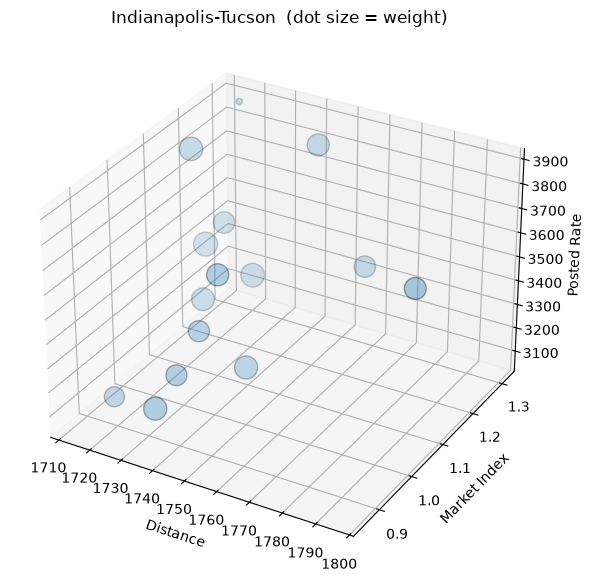

In [34]:

# Same route selection code as before, then:

# Drop rows missing any of the 4 columns used in the plot
# (dropna(subset=...): removes rows where those specific columns are NaN)
plot_df = route_df.dropna(subset=['distance', 'market_index', 'posted_rate', 'weight'])

# Turn weight into dot sizes: scale to 20-300 so small and large weights are both visible
# (a raw weight like 20000 would give giant dots)
w = plot_df['weight'].astype(float)
w_range = w.max() - w.min()
# if all weights are equal, w_range is 0, so fall back to a fixed size
sizes = 20 + 280 * (w - w.min()) / w_range if w_range > 0 else 100

# figure(): creates the canvas; add_subplot(projection='3d'): adds a 3D axes to it
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection='3d')

# scatter(x, y, z, s=sizes): one dot per row, s controls dot size
# alpha=0.6 makes dots semi-transparent so overlapping ones stay visible
ax.scatter(plot_df['distance'], plot_df['market_index'], plot_df['posted_rate'],
           s=sizes, alpha=0.6, edgecolor='k')

# Axis labels and title
ax.set_xlabel('Distance')
ax.set_ylabel('Market Index')
ax.set_zlabel('Posted Rate')
ax.set_title(f'{random_route_name}  (dot size = weight)')

plt.show()

### 1.1.4 Date Analysis

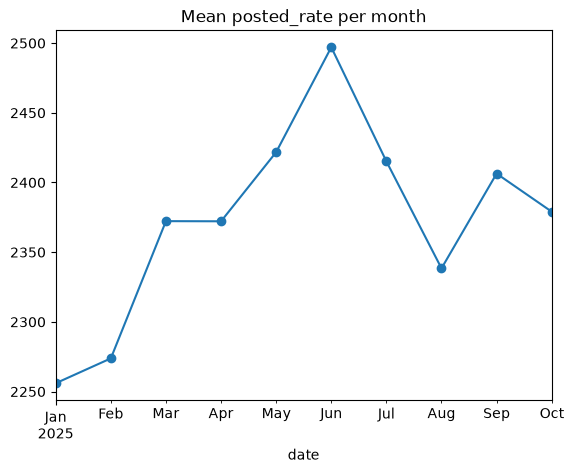

date
0    2349.308676
1    2372.890626
2    2405.086706
3    2403.265599
4    2376.849855
5    2373.714334
6    2335.073176
Name: posted_rate, dtype: float64
date
1     2255.967048
2     2273.804801
3     2372.268092
4     2372.162308
5     2421.776342
6     2497.030115
7     2415.162030
8     2338.407661
9     2406.374013
10    2379.051374
Name: posted_rate, dtype: float64


In [35]:
df = train_test_df.copy()

# to_datetime(): converts the text column to real dates so pandas can group by month, weekday, etc.
df['date'] = pd.to_datetime(df['date'])

# Mean posted_rate per month: a trend or seasonal pattern shows up as a moving line
# dt.to_period('M'): rounds each date to its month; groupby + mean: average rate per month
monthly = df.groupby(df['date'].dt.to_period('M'))['posted_rate'].mean()
monthly.plot(marker='o', title='Mean posted_rate per month')
plt.show()

# Same idea per weekday (0 = Monday) and per month number (1-12, shows seasonality across years)
print(df.groupby(df['date'].dt.dayofweek)['posted_rate'].mean())
print(df.groupby(df['date'].dt.month)['posted_rate'].mean())

#### 1.1.4 Equipement Analysis

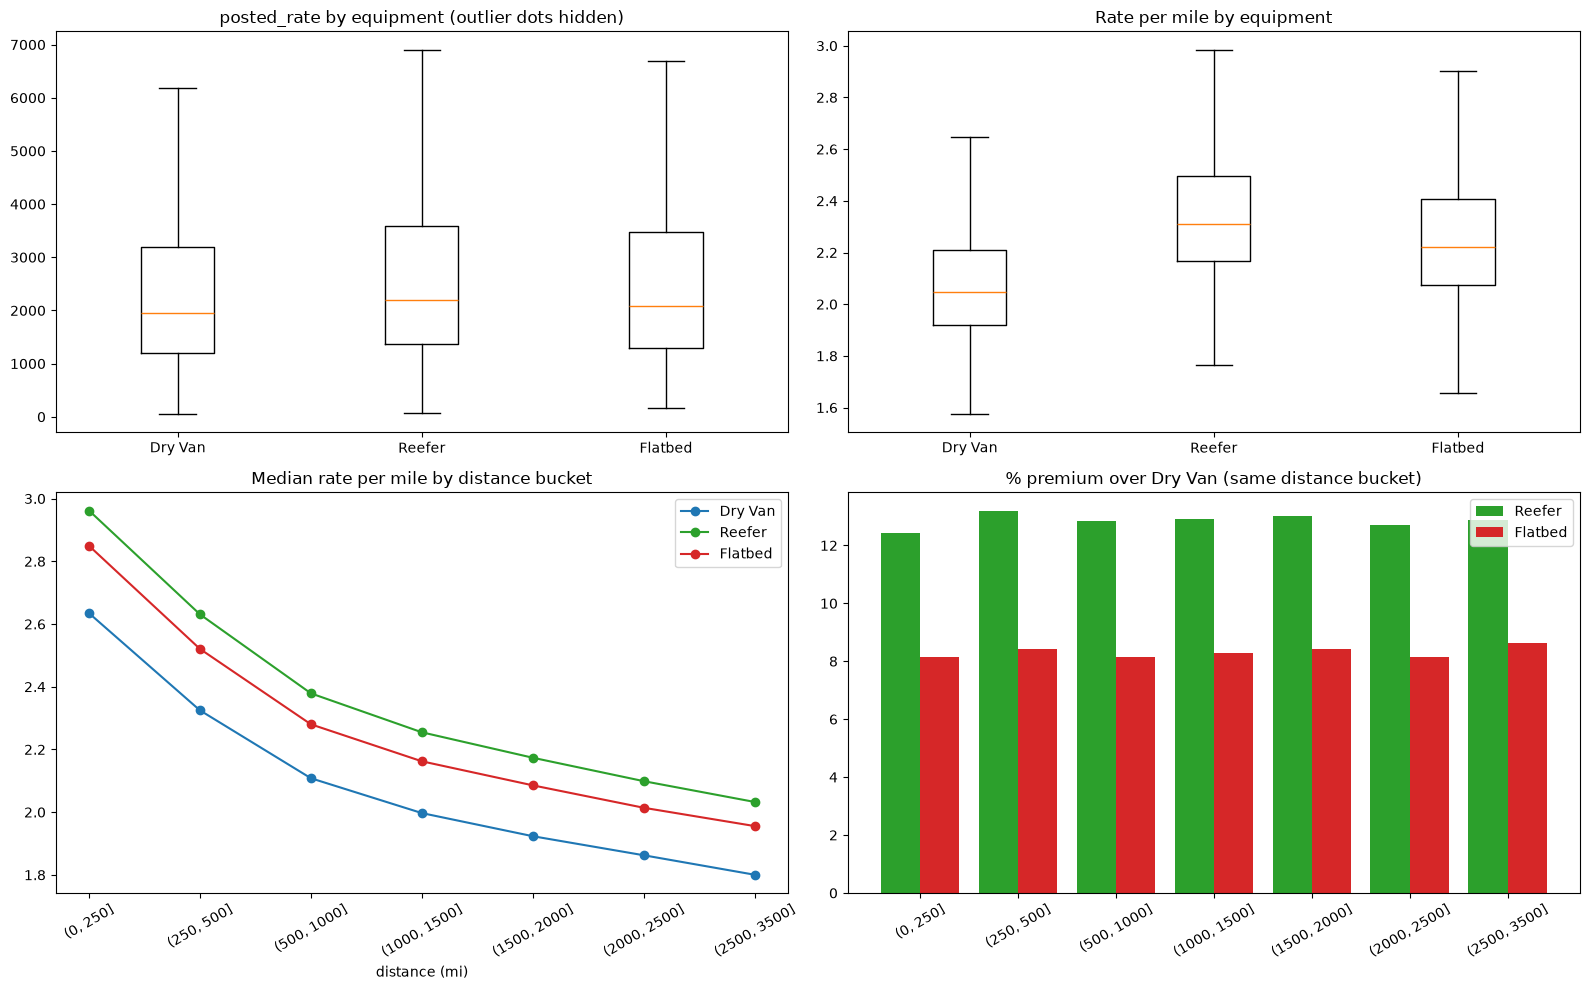

,posted_rate,rpm,distance,n_loads,rpm_premium_vs_dry_van_%
equipment,,,,,
Dry Van,1953.04,2.05,957.55,27202,0.0
Reefer,2196.67,2.31,950.20,12045,12.7
Flatbed,2076.81,2.22,940.00,8753,8.3


Premium over Dry Van by distance bucket (%):


dist_bin,"(0, 250]","(250, 500]","(500, 1000]","(1000, 1500]","(1500, 2000]","(2000, 2500]","(2500, 3500]"
equipment,,,,,,,
Reefer,12.4,13.2,12.8,12.9,13.0,12.7,12.9
Flatbed,8.2,8.4,8.2,8.3,8.4,8.1,8.6


In [36]:
d = train_test_df.copy()   # use cleaned data if Cell I has run
d["rpm"] = d["posted_rate"] / d["distance"]
equip = ["Dry Van", "Reefer", "Flatbed"]
colors = {"Dry Van": "tab:blue", "Reefer": "tab:green", "Flatbed": "tab:red"}

# Distance buckets so we compare like with like
bins = [0, 250, 500, 1000, 1500, 2000, 2500, 3500]
d["dist_bin"] = pd.cut(d["distance"], bins)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Raw posted_rate by equipment
axes[0, 0].boxplot([d.loc[d.equipment == e, "posted_rate"] for e in equip], tick_labels=equip, showfliers=False)
axes[0, 0].set_title("posted_rate by equipment (outlier dots hidden)")

# 2. Rate per mile by equipment
axes[0, 1].boxplot([d.loc[d.equipment == e, "rpm"] for e in equip], tick_labels=equip, showfliers=False)
axes[0, 1].set_title("Rate per mile by equipment")

# 3. Median rate per mile across distance buckets
rpm_bin = d.groupby(["dist_bin", "equipment"], observed=True)["rpm"].median().unstack()[equip]
for e in equip:
    axes[1, 0].plot(range(len(rpm_bin)), rpm_bin[e], marker="o", color=colors[e], label=e)
axes[1, 0].set_xticks(range(len(rpm_bin)), [str(b) for b in rpm_bin.index], rotation=30)
axes[1, 0].set_title("Median rate per mile by distance bucket"); axes[1, 0].set_xlabel("distance (mi)")
axes[1, 0].legend()

# 4. Premium over Dry Van at the same distance
prem = rpm_bin[["Reefer", "Flatbed"]].div(rpm_bin["Dry Van"], axis=0).sub(1).mul(100)
x = np.arange(len(prem))
axes[1, 1].bar(x - .2, prem["Reefer"], .4, color=colors["Reefer"], label="Reefer")
axes[1, 1].bar(x + .2, prem["Flatbed"], .4, color=colors["Flatbed"], label="Flatbed")
axes[1, 1].set_xticks(x, [str(b) for b in prem.index], rotation=30)
axes[1, 1].axhline(0, color="k", lw=.5)
axes[1, 1].set_title("% premium over Dry Van (same distance bucket)"); axes[1, 1].legend()

plt.tight_layout(); plt.show()

# Summary tables
summary = d.groupby("equipment")[["posted_rate", "rpm", "distance"]].median().loc[equip].round(2)
summary["n_loads"] = d["equipment"].value_counts()[equip]
summary["rpm_premium_vs_dry_van_%"] = ((summary["rpm"] / summary.loc["Dry Van", "rpm"] - 1) * 100).round(1)
display(summary)
print("Premium over Dry Van by distance bucket (%):")
display(prem.round(1).T)


### 2.0 Visual Analysis
#### 2.1. Plotting all distributions for each features

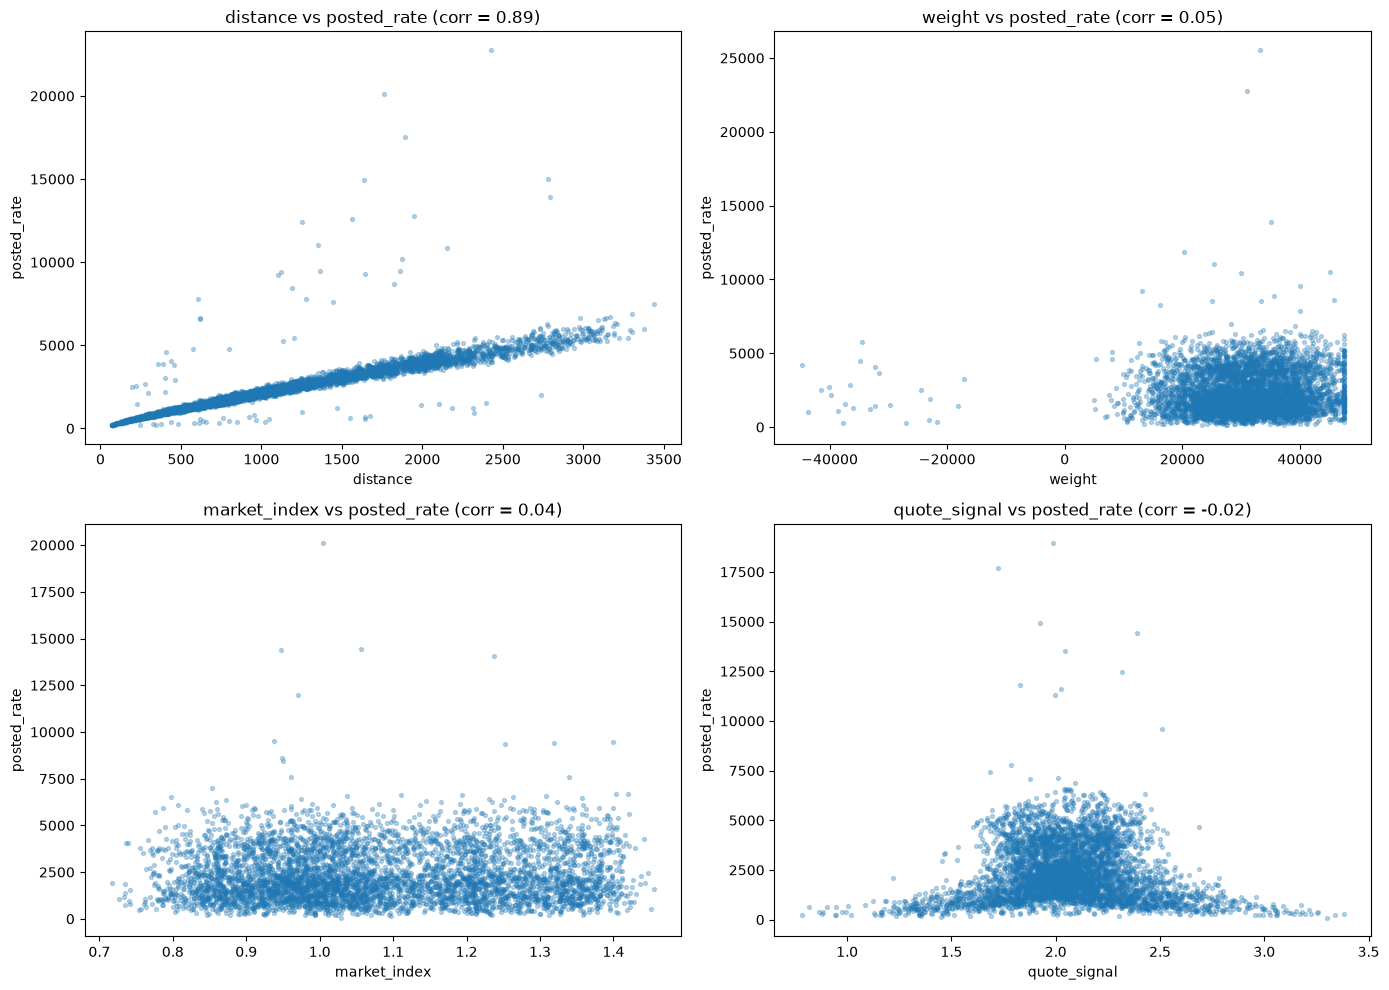

In [37]:
features = ['distance', 'weight', 'market_index', 'quote_signal']

# subplots(rows, cols): creates a grid of plots; returns the figure and an array of axes
# figsize=(14, 10): size of the whole canvas in inches
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# axes is a 2x2 array; flatten() turns it into a 1D list of 4 axes so we can loop over it
axes = axes.flatten()

# zip pairs each feature name with one axis: (distance, ax0), (weight, ax1), ...
for feature, ax in zip(features, axes):
    # Keep only rows where both the feature and posted_rate exist
    # (dropna(subset=...): removes rows with NaN in those columns)
    data = train_test_df[[feature, 'posted_rate']].dropna()

    # If there are many rows, plot a random 5000 so the plot stays fast and readable
    # (sample(n): random rows; min() avoids asking for more rows than exist)
    data = data.sample(n=min(5000, len(data)))

    # scatter(x, y): one dot per row
    # s=8: small dots, alpha=0.3: semi-transparent so dense areas look darker
    ax.scatter(data[feature], data['posted_rate'], s=8, alpha=0.3)

    # Label the axes and add a title with the Pearson correlation for this feature
    # (corr(): correlation between two columns, from -1 to 1)
    ax.set_xlabel(feature)
    ax.set_ylabel('posted_rate')
    ax.set_title(f"{feature} vs posted_rate (corr = {data[feature].corr(data['posted_rate']):.2f})")

# tight_layout(): adjusts spacing so titles and labels don't overlap
plt.tight_layout()
plt.show()

In [38]:
# confirm the cap
print(train_test_df['weight'].value_counts().head())

cap = train_test_df['weight'].max()   # the suspected cap value
n_capped = (train_test_df['weight'] == cap).sum()   # rows sitting exactly at the cap
print(cap, n_capped, f"{n_capped / len(train_test_df):.1%} of rows")

weight
 47500.0    1191
 5000.0       31
-47500.0      13
 32436.0      10
 32153.0      10
Name: count, dtype: int64
47500.0 1191 2.5% of rows


In [39]:
# confirm the cap
print(validation_df['weight'].value_counts().head())

cap = validation_df['weight'].max()   # the suspected cap value
n_capped = (validation_df['weight'] == cap).sum()   # rows sitting exactly at the cap
print(cap, n_capped, f"{n_capped / len(validation_df):.1%} of rows")

weight
47500.0    297
5000.0       7
27854.0      5
36431.0      5
40841.0      4
Name: count, dtype: int64
47500.0 297 2.5% of rows


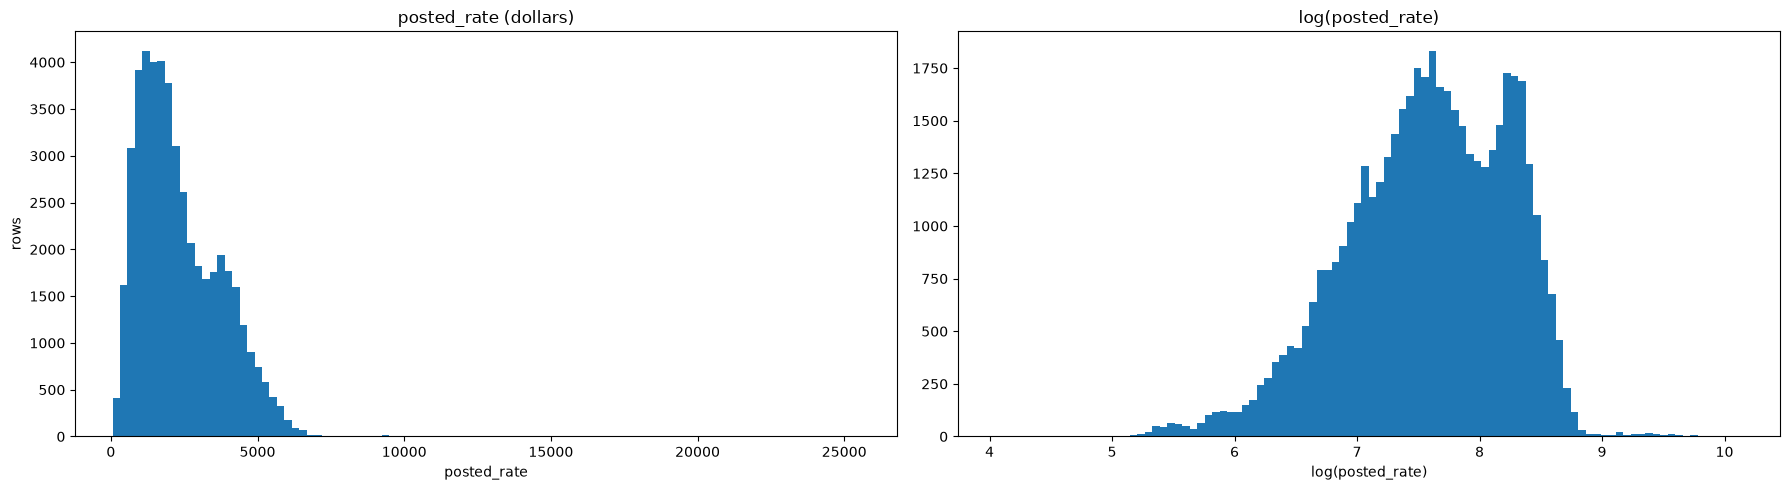

skew raw: 1.9 | skew log: -0.49


In [40]:
df = train_test_df.copy()
df['date'] = pd.to_datetime(df['date'])        # text -> real dates

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 1. Distribution in dollars
# hist(x, bins=100): bar chart of how many rows fall in each value range
axes[0].hist(df['posted_rate'], bins=100)
axes[0].set_title('posted_rate (dollars)')
axes[0].set_xlabel('posted_rate')
axes[0].set_ylabel('rows')

# 2. Distribution of log(posted_rate)
# np.log: natural log of every value
axes[1].hist(np.log(df['posted_rate']), bins=100)
axes[1].set_title('log(posted_rate)')
axes[1].set_xlabel('log(posted_rate)')


plt.tight_layout()
plt.show()

# Numbers to go with the plots
# skew(): > 0 means a long tail to the right, near 0 means symmetric
print('skew raw:', df['posted_rate'].skew().round(2), '| skew log:', np.log(df['posted_rate']).skew().round(2))

#### 2.2 Box Plots

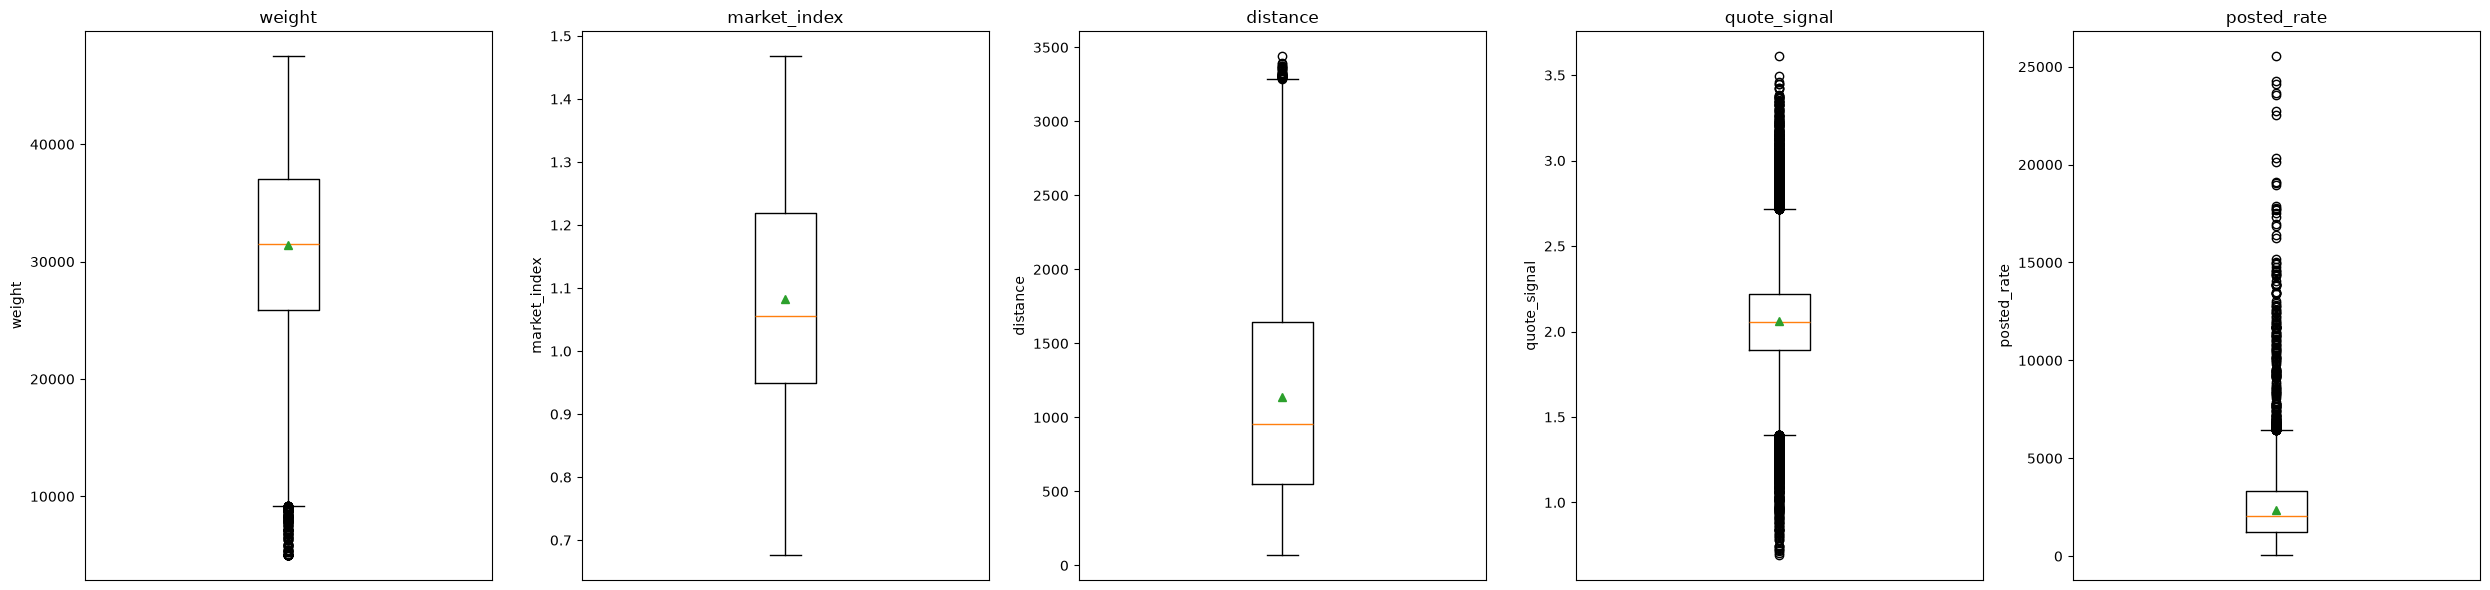

In [49]:
features = ['weight', 'market_index', 'distance', 'quote_signal', 'posted_rate']

# copy(): plot_df is a separate dataframe, so train_test_df keeps its original values
plot_df = train_test_df.copy()

# abs(): turns -47500 into 47500 (NaN stays NaN)
plot_df['weight'] = plot_df['weight'].abs()

fig, axes = plt.subplots(1, len(features), figsize=(5 * len(features), 6), squeeze=False)
axes = axes[0]

for feature, ax in zip(features, axes):
    # Same box plot as before, now reading from plot_df
    ax.boxplot(plot_df[feature].dropna(), showmeans=True)
    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

expected = e^( start + slope * ln(distance) + equipment shift ), fitted on all loads


,fitted
ln_distance,0.871
start,1.606
is_Flatbed,0.079
is_Reefer,0.118


,median price 800-1200 mi,data vs Dry Van %,formula vs Dry Van %
Dry Van,1991.22,0.0,0.0
Flatbed,2140.40,7.5,8.2
Reefer,2244.63,12.7,12.5


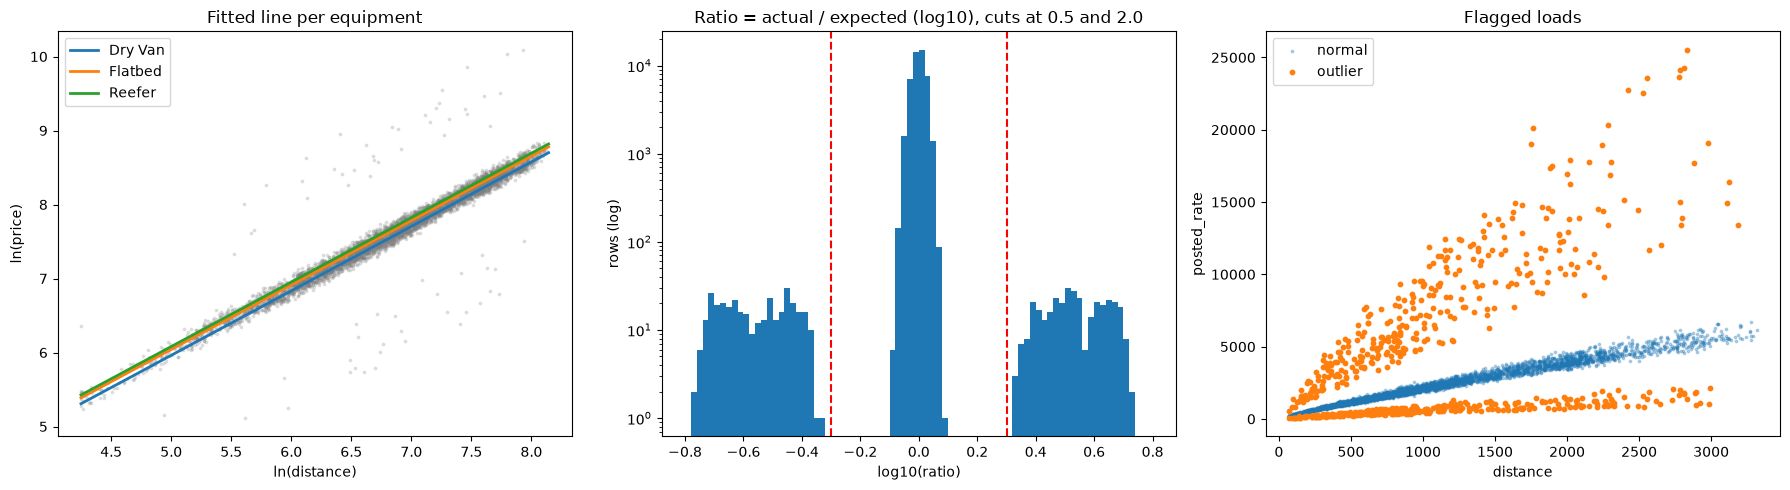

SUMMARY
Slope 0.871: doubling distance multiplies price by 1.83. Start 1.606 only sets the line height.
Equipment: Flatbed +0.079, Reefer +0.118, Dry Van is the baseline (0).
Outliers: 677 of 48,000 rows = 1.41% (337 too cheap, 340 too expensive)
By quarter:  2025Q1 1.46%, 2025Q2 1.32%, 2025Q3 1.37%, 2025Q4 1.65%
By equipment: Dry Van 1.35%, Flatbed 1.45%, Reefer 1.51%
Dropped from training rows only; the formula is refit inside each fold.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = train_test_df.copy()
df['quarter'] = pd.to_datetime(df['date']).dt.to_period('Q').astype(str)
df['ln_distance'] = np.log(df['distance'])
df['ln_price'] = np.log(df['posted_rate'])
sample = df.sample(5000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sample['distance'], sample['posted_rate'], s=4, alpha=0.3)
axes[0].set(title='Before: distance vs price (curved band)', xlabel='distance', ylabel='posted_rate')
axes[1].scatter(sample['ln_distance'], sample['ln_price'], s=4, alpha=0.3)
axes[1].set(title='After: ln(distance) vs ln(price) (straight band)', xlabel='ln(distance)', ylabel='ln(price)')
plt.tight_layout()
plt.show()

van = df[df['equipment'] == 'Dry Van']
a, b = van.iloc[0], van.iloc[1]
two_slope = (b['ln_price'] - a['ln_price']) / (b['ln_distance'] - a['ln_distance'])
two_start = a['ln_price'] - two_slope * a['ln_distance']
print("ln(price) = start + slope * ln(distance)")
print(f"Two loads ({a['distance']:.1f} mi ${a['posted_rate']:.2f}, {b['distance']:.1f} mi ${b['posted_rate']:.2f}): "
      f"slope {two_slope:.3f}, start {two_start:.3f}")

others = ['Flatbed', 'Reefer']
X = pd.DataFrame({'ln_distance': df['ln_distance'], 'start': 1.0})
for e in others:
    X['is_' + e] = (df['equipment'] == e).astype(float)
coef = pd.Series(np.linalg.lstsq(X.values, df['ln_price'].values, rcond=None)[0], index=X.columns)
slope, start = coef['ln_distance'], coef['start']
shift = {'Dry Van': 0.0, 'Flatbed': coef['is_Flatbed'], 'Reefer': coef['is_Reefer']}
print("All loads (least squares):")
display(coef.round(3).to_frame('fitted'))

x = np.linspace(df['ln_distance'].min(), df['ln_distance'].max(), 50)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sample['ln_distance'], sample['ln_price'], s=3, alpha=0.2, color='gray')
axes[0].plot(x, two_start + two_slope * x, color='red', linewidth=2, label=f'two loads: slope {two_slope:.3f}')
axes[0].plot(x, start + slope * x, color='blue', linewidth=2, label=f'all loads: slope {slope:.3f}')
axes[0].scatter([a['ln_distance'], b['ln_distance']], [a['ln_price'], b['ln_price']], color='red', s=60, zorder=5)
axes[0].set(title='Line from two loads vs all loads (Dry Van)', xlabel='ln(distance)', ylabel='ln(price)')
axes[0].legend()
axes[1].scatter(sample['ln_distance'], sample['ln_price'], s=3, alpha=0.2, color='gray')
for e, s in shift.items():
    axes[1].plot(x, start + slope * x + s, linewidth=2, label=f'{e} (+{s:.3f})')
axes[1].set(title='Same slope, equipment shifts the line', xlabel='ln(distance)', ylabel='ln(price)')
axes[1].legend()
plt.tight_layout()
plt.show()

df['expected'] = np.exp(start + slope * df['ln_distance'] + df['equipment'].map(shift))
df['ratio'] = df['posted_rate'] / df['expected']
df['too_cheap'] = df['ratio'] < 0.5
df['too_expensive'] = df['ratio'] > 2.0
df['outlier'] = df['too_cheap'] | df['too_expensive']

median = df[~df['outlier'] & df['distance'].between(800, 1200)].groupby('equipment')['posted_rate'].median()
check = pd.DataFrame({
    'median price 800-1200 mi': median,
    'data vs Dry Van %': ((median / median['Dry Van'] - 1) * 100).round(1),
    'formula vs Dry Van %': pd.Series({e: (np.exp(s) - 1) * 100 for e, s in shift.items()}).round(1),
})
display(check)
ax = check[['data vs Dry Van %', 'formula vs Dry Van %']].plot.bar(figsize=(7, 4), rot=0)
ax.set(title='Equipment effect: data vs formula', ylabel='% more expensive than Dry Van')
plt.show()

print("expected = e^( start + slope * ln(distance) + equipment shift )")
table = pd.DataFrame({e: [np.exp(start + slope * np.log(m) + s) for m in (300, 1000, 2000)] for e, s in shift.items()},
                     index=['300 mi', '1,000 mi', '2,000 mi'])
display(table.round(0))
reefer = table.loc['1,000 mi', 'Reefer']
print(f"Example: 1,000-mile Reefer posted at $1,100 -> ratio 1,100 / {reefer:,.0f} = {1100 / reefer:.2f}, below 0.5, outlier")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(np.log10(df['ratio']), bins=np.linspace(-0.8, 0.8, 81))
axes[0].set_yscale('log')
axes[0].axvline(np.log10(0.5), color='red', linestyle='--')
axes[0].axvline(np.log10(2.0), color='red', linestyle='--')
axes[0].set(title='Ratio = actual / expected (log10), cuts at 0.5 and 2.0', xlabel='log10(ratio)', ylabel='rows (log)')
ok = df[~df['outlier']].sample(4000, random_state=0)
bad = df[df['outlier']]
axes[1].scatter(ok['distance'], ok['posted_rate'], s=3, alpha=0.3, label='normal')
axes[1].scatter(bad['distance'], bad['posted_rate'], s=10, color='tab:orange', label='outlier')
axes[1].set(title='Flagged loads', xlabel='distance', ylabel='posted_rate')
axes[1].legend()
plt.tight_layout()
plt.show()

by_quarter = df.groupby('quarter')['outlier'].mean() * 100
by_equipment = df.groupby('equipment')['outlier'].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_quarter.index, by_quarter.values)
axes[0].set(title='% flagged per quarter', ylabel='%')
axes[1].bar(by_equipment.index, by_equipment.values)
axes[1].set(title='% flagged per equipment', ylabel='%')
plt.tight_layout()
plt.show()

print("SUMMARY")
print(f"Slope {slope:.3f}: doubling distance multiplies price by {2 ** slope:.2f}. Start {start:.3f} only sets the line height.")
print(f"Equipment: Flatbed +{shift['Flatbed']:.3f}, Reefer +{shift['Reefer']:.3f}, Dry Van is the baseline (0).")
print(f"Outliers: {df['outlier'].sum():,} of {len(df):,} rows = {df['outlier'].mean():.2%} "
      f"({df['too_cheap'].sum()} too cheap = {df['too_cheap'].mean():.2%}, {df['too_expensive'].sum()} too expensive = {df['too_expensive'].mean():.2%})")
print(f"Loads with ratio between 0.8 and 1.25: {df['ratio'].between(0.8, 1.25).mean():.2%}")
print("By quarter:   " + ", ".join(f"{k} {v:.2f}%" for k, v in by_quarter.items()))
print("By equipment: " + ", ".join(f"{k} {v:.2f}%" for k, v in by_equipment.items()))
print("Analysis only: no rows are removed here. In training, outliers are dropped from the train rows only.")

## Data Preprocessing

In [42]:
def drop_columns(X, drop_cols):
    return X.drop(columns=drop_cols, errors='ignore')

# Step 2: fix negative weights
def abs_weight(X):
    X = X.copy()                      # copy(): never modify the caller's dataframe
    X['weight'] = X['weight'].abs()   # abs(): -47500 -> 47500, NaN stays NaN
    return X

# Step 3: Imputer
class GroupImputer(BaseEstimator, TransformerMixin):
    """Fill missing values in `cols`.
    group_by: list of columns to group by (None = no grouping, use the whole column)
    strategy: 'mean', 'median' or 'zero'
    """
    def __init__(self, cols, group_by=None, strategy='median'):
        self.cols = cols
        self.group_by = group_by
        self.strategy = strategy

    def fit(self, X, y=None):
        cols = list(self.cols)

        # Global fallback value per column (used when a group is unseen or has only NaN)
        if self.strategy == 'zero':
            self.global_ = pd.Series(0.0, index=cols)    # fill with 0 everywhere
        else:
            # getattr(X[cols], 'median'): picks the .mean() or .median() method by name
            self.global_ = getattr(X[cols], self.strategy)()

        # Per-group value, learned from train only (skipped for 'zero' or no grouping)
        self.stats_ = None
        if self.group_by and self.strategy != 'zero':
            # groupby(...)[cols].median(): one value per group per column, NaN ignored
            # reset_index(): turns the group labels back into normal columns so we can merge on them
            self.stats_ = getattr(X.groupby(list(self.group_by))[cols], self.strategy)().reset_index()
        return self

    def transform(self, X):
        X = X.copy()                                     # never modify the caller's dataframe
        for c in self.cols:
            filled = X[c]
            if self.stats_ is not None:
                # merge(how='left'): attaches each row's group value, keeps row order, NaN if the group is unseen
                group_vals = X[list(self.group_by)].merge(
                    self.stats_[list(self.group_by) + [c]], on=list(self.group_by), how='left')[c].values
                # fillna(group value): try the group value first
                filled = filled.fillna(pd.Series(group_vals, index=X.index))
            X[c] = filled.fillna(self.global_[c])        # then fall back to the global value
        return X

# Step 4 : outlier removal
# Expected-price formula from distance + equipment, fitted on the rows you give it
def design(df, equipment_levels):
    X = pd.DataFrame({'log_dist': np.log(df['distance']), 'const': 1.0}, index=df.index)
    for e in equipment_levels:                       # one 0/1 column per equipment, first level is the baseline
        X['eq_' + e] = (df['equipment'] == e).astype(float)
    return X

def outlier_flags(train_df, other_df=None, low=0.5, high=2.0):
    levels = sorted(train_df['equipment'].unique())[1:]
    Xtr = design(train_df, levels)
    # lstsq: least-squares fit of log(rate) on the design matrix -> beta (the formula's coefficients)
    beta, *_ = np.linalg.lstsq(Xtr.values, np.log(train_df['posted_rate']).values, rcond=None)
    def flag(df):
        ratio = df['posted_rate'] / np.exp(design(df, levels).values @ beta)   # actual / expected
        return ((ratio < low) | (ratio > high)).values                          # True = outlier
    return flag(train_df), (flag(other_df) if other_df is not None else None)


In [43]:
drop_list = ['load_id', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']

weight_branch = Pipeline([
    ('abs', FunctionTransformer(np.abs)),      # -47500 -> 47500
    ('scale', StandardScaler()),
])

# Wrapper: trains the inner model on log(y), and applies exp() to its predictions
log_model = TransformedTargetRegressor(
    regressor=XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                           subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1),
    func=np.log,           # y -> log(y), applied to posted_rate before training
    inverse_func=np.exp,   # log prediction -> dollars, applied automatically in predict()
)


prep = ColumnTransformer([
    ('weight', weight_branch, ['weight']),
    ('num', StandardScaler(), ['distance', 'market_index', 'quote_signal']),
    ('cat', Pipeline([
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), ['equipment']),
], remainder='drop')   # pickup, delivery, date, quarter are dropped here

pipe = Pipeline([
    ('drop', FunctionTransformer(drop_columns, kw_args={'drop_cols': drop_list})),
    ('imp_weight', GroupImputer(cols=['weight'], group_by=['pickup', 'delivery'], strategy='median')),
    ('imp_market', GroupImputer(cols=['market_index'], group_by=['pickup', 'delivery'], strategy='mean')),
    ('prep', prep),
    ('model', log_model),
])


In [51]:
d = train_test_df.copy()
d['date'] = pd.to_datetime(d['date'])                     # text -> real dates
d['quarter'] = d['date'].dt.to_period('Q').astype(str)    # e.g. '2025Q1'

X = d.drop(columns='posted_rate')   # raw features; the ColumnTransformer ignores 'date' and 'quarter'
y = d['posted_rate']                # target
groups = d['quarter']               # the fold label of each row

logo = LeaveOneGroupOut()           # one fold per quarter, each holds out one whole quarter

results = []
for train_idx, test_idx in logo.split(X, y, groups):
    held_out = groups.iloc[test_idx].iloc[0]       # name of the quarter held out in this fold

    # NEW: flag outliers with a formula learned from THIS fold's train rows only
    # (d, not X, because the formula needs posted_rate)
    bad_tr, bad_te = outlier_flags(d.iloc[train_idx], d.iloc[test_idx])
    kept_idx = train_idx[~bad_tr]                  # NEW: training rows without outliers (test rows are not trimmed)

    # clone(): fresh unfitted pipeline, so all statistics come from this fold's kept train rows only
    fold_pipe = clone(pipe)
    fold_pipe.fit(X.iloc[kept_idx], y.iloc[kept_idx])          # CHANGED: kept_idx instead of train_idx

    pred_tr = fold_pipe.predict(X.iloc[kept_idx])              # predictions on the kept train rows
    pred_te = fold_pipe.predict(X.iloc[test_idx])              # predictions on the held-out quarter
    y_te = y.iloc[test_idx].values                             # true test rates as a numpy array

    train_mae = mean_absolute_error(y.iloc[kept_idx], pred_tr)
    test_mae = mean_absolute_error(y_te, pred_te)                          # all test rows (honest number)
    test_mae_clean = mean_absolute_error(y_te[~bad_te], pred_te[~bad_te])  # NEW: without outlier rows (comparable to the old results)

    results.append((held_out, len(test_idx), bad_tr.mean() * 100, train_mae, test_mae, test_mae_clean))

res = pd.DataFrame(results, columns=['quarter', 'rows', 'train_dropped_%', 'train_MAE', 'test_MAE', 'test_MAE_clean'])
res['gap'] = res['test_MAE'] - res['train_MAE']    # large gap = overfitting or a shifted quarter
display(res.round(2))

print('mean test MAE        :', res['test_MAE'].mean().round(2))                                  # each fold counts equally
print('row-weighted test MAE:', np.average(res['test_MAE'], weights=res['rows']).round(2))        # bigger folds count more
print('mean test MAE (clean):', res['test_MAE_clean'].mean().round(2))                            # NEW
print('mean train MAE       :', res['train_MAE'].mean().round(2))

,quarter,rows,train_dropped_%,train_MAE,test_MAE,test_MAE_clean,gap
0,2025Q1,14291,1.39,40.73,120.71,76.25,79.97
1,2025Q2,14515,1.45,42.53,104.74,55.07,62.21
2,2025Q3,14341,1.43,36.72,119.43,68.01,82.72
3,2025Q4,4853,1.38,41.66,133.64,73.56,91.98


mean test MAE        : 119.63
row-weighted test MAE: 116.81
mean test MAE (clean): 68.22
mean train MAE       : 40.41
